# Chapter 6 Context Engineering

In [4]:
import os
import re
import sys
import time

from dotenv import load_dotenv
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from psycopg.rows import dict_row
from psycopg_pool import ConnectionPool

load_dotenv()

model = ChatOpenAI(
    model=os.getenv("LLM_MODEL_ID", "deepseek-flash"),
    api_key=os.getenv("LLM_API_KEY"),
    base_url=os.getenv("LLM_BASE_URL", "https://api.deepseek.com"),
    temperature=0,
    timeout=60, max_retries=2,          # without a timeout a stuck request waits forever
    extra_body={"thinking": {"type": "disabled"}},
)
embeddings = OpenAIEmbeddings(model="bge-m3", base_url="http://localhost:11434/v1", api_key="ollama",
                              check_embedding_ctx_length=False)
pool = ConnectionPool(os.getenv("DATABASE_URL"), max_size=10, open=True,
                      kwargs={"autocommit": True, "prepare_threshold": 0, "row_factory": dict_row})

In [5]:
from rank_bm25 import BM25Okapi

COLUMNS = "id, chapter_no, page, content"


def vector_search(query: str, k: int = 10, chapter_no: int | None = None) -> list[dict]:
    qv = str(embeddings.embed_query(query))
    where = "WHERE chapter_no = %(ch)s" if chapter_no else ""
    with pool.connection() as conn:
        return conn.execute(f"SELECT {COLUMNS}, 1 - (embedding <=> %(qv)s::vector) AS score FROM doc_chunks {where} "
                            "ORDER BY embedding <=> %(qv)s::vector LIMIT %(k)s",
                            {"qv": qv, "k": k, "ch": chapter_no}).fetchall()


def tokenize(text: str) -> list[str]:
    return re.findall(r"[a-z0-9_]+", text.lower())


with pool.connection() as conn:
    corpus = conn.execute(f"SELECT {COLUMNS} FROM doc_chunks ORDER BY id").fetchall()
bm25 = BM25Okapi([tokenize(d["content"]) for d in corpus])


def bm25_search(query: str, k: int = 10, chapter_no: int | None = None) -> list[dict]:
    scores = bm25.get_scores(tokenize(query))
    results = []
    for i in scores.argsort()[::-1]:
        if scores[i] <= 0 or len(results) == k:
            break
        if chapter_no is None or corpus[i]["chapter_no"] == chapter_no:
            results.append(corpus[i] | {"score": float(scores[i])})
    return results


def rrf(result_lists: list[list[dict]], k: int = 5, c: int = 60) -> list[dict]:
    scores, docs = {}, {}
    for results in result_lists:
        for rank, d in enumerate(results, 1):
            scores[d["id"]] = scores.get(d["id"], 0) + 1 / (c + rank)
            docs[d["id"]] = d
    best = sorted(scores, key=scores.get, reverse=True)[:k]
    return [docs[i] | {"score": scores[i]} for i in best]


def hybrid_search(query: str, k: int = 5, chapter_no: int | None = None) -> list[dict]:
    return rrf([vector_search(query, 20, chapter_no), bm25_search(query, 20, chapter_no)], k)


print(len(corpus), "chunks;", [d["page"] for d in hybrid_search("GSSC pipeline")])

1834 chunks; [374, 432, 432, 431, 366]


## 1. The concept of Contexxt

context is all the token passed into the model each time it is invoked.
- System prompt
- Tool definitions
- User memories and passaages retrieved by RAG
- Conversation history
- The results returned by every prebious tool call

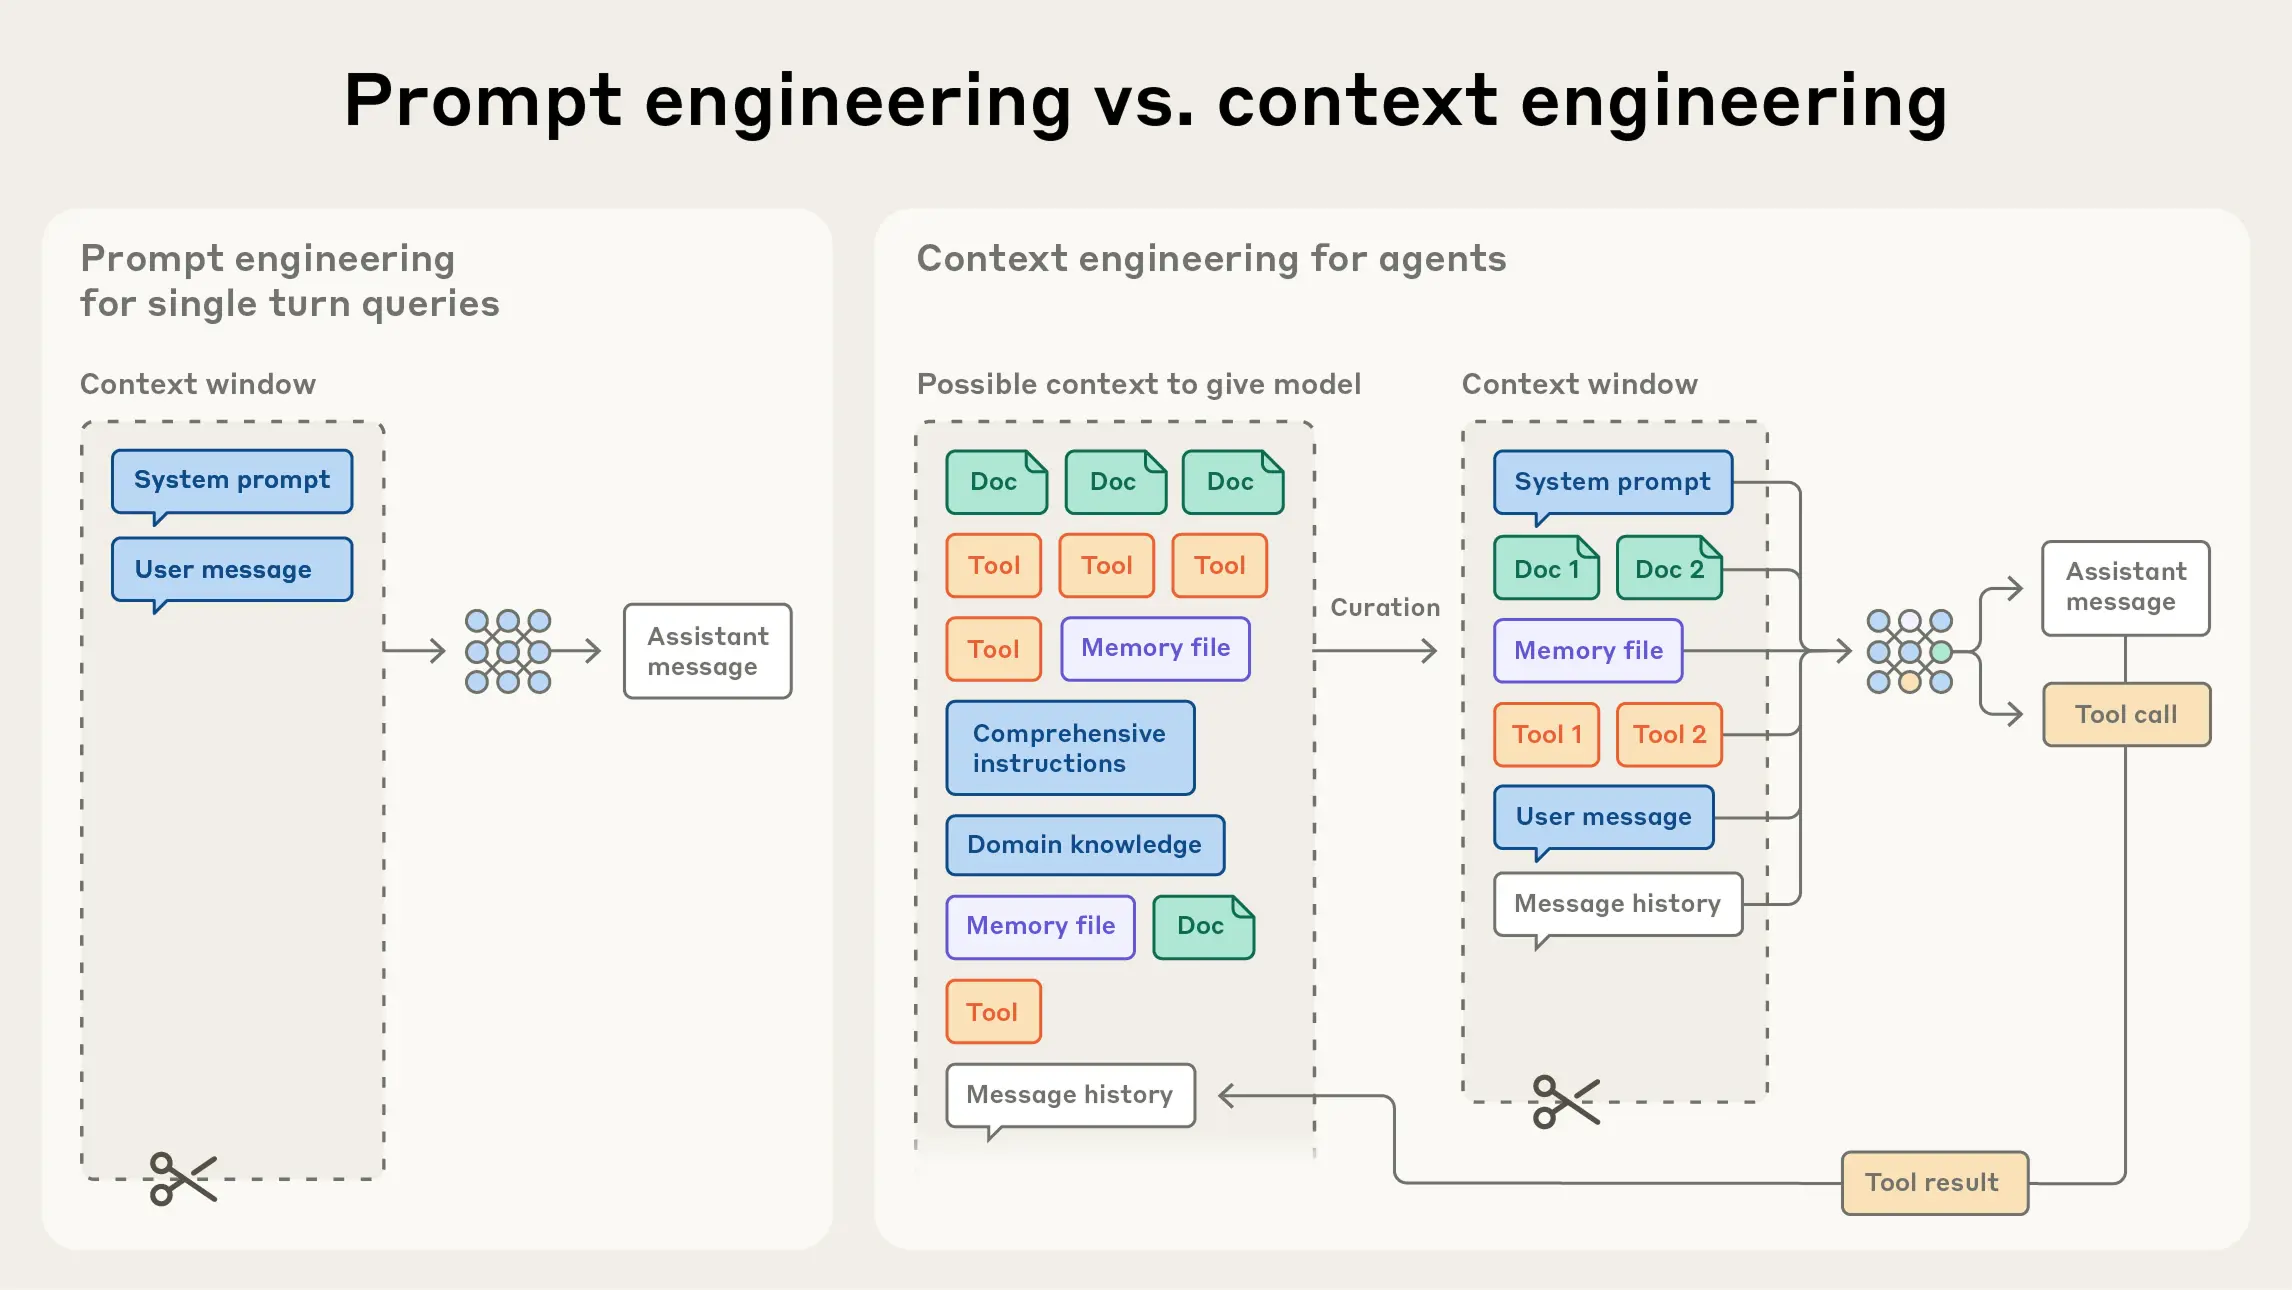

**Context engineer vs prompt engineer**


|  | Prompt Engineering | Context Engineering |
|---|---|---|
| **What it focuses on** | How to write instructions clearly | How to select, order, and budget-control the information sent into the model each turn |
| **At which stage it applies** | Mainly when writing the system prompt | Continuously throughout the entire Agent execution loop |
| **Core question** | "How to say it" | "What to show the model and what not to show it" |

Every time an Agent runs a trun, it generates new information, such as tool return results and intermidiate reasoning. What context engineering aims to solve is how to select, from this ever-growing pool of candidate information, the portion most worth placing into the limited context window

## 2. Context Rot

Context rot refers a phenomenon: as the amount of context fed into the model continues to grow, the model's performance actually decreases rather than improves,

In [6]:
import random

with pool.connection() as conn:
    filler = [r["content"] for r in conn.execute("SELECT content FROM doc_chunks ORDER BY page, id")]

NEEDLES = {f"Room {n}": code for n, code in zip([3, 8, 14, 21, 27, 33, 40, 46],
                                                ["K7Q", "B2M", "Z9P", "H4T", "R6W", "C1L", "V8N", "J3F"])}
UPDATES = {"Room 8": "B5X", "Room 21": "H9K", "Room 33": "C7D", "Room 46": "J8Q"}
CURRENT = NEEDLES | UPDATES
DISTRACTORS = [f"Reminder: the locker number for {room} is {code[::-1]}." for room, code in list(NEEDLES.items())[::2]]


def take_filler(target_tokens: int) -> list[str]:
    chunks, size = [], 0
    for text in filler:                     # real tutorial text, ~4 characters per token
        if size >= target_tokens * 4:
            break
        chunks.append(text)
        size += len(text)
    return chunks


def easy_haystack(target_tokens: int) -> str:
    """Needles spread evenly; each room has one code."""
    chunks = take_filler(target_tokens)
    slots = [round(i * (len(chunks) - 1) / (len(NEEDLES) - 1)) for i in range(len(NEEDLES))]
    for slot, (room, code) in zip(reversed(slots), reversed(list(NEEDLES.items()))):
        chunks.insert(slot, f"Note for the facilities team: the door code for {room} is {code}.")
    return "\n\n".join(chunks)


def hard_haystack(target_tokens: int, seed: int) -> str:
    """Original codes early, updates later, plus look-alike locker numbers anywhere."""
    chunks = take_filler(target_tokens)
    notes = ([f"Note for the facilities team: the door code for {r} is {c}." for r, c in NEEDLES.items()]
             + [f"Update for the facilities team: the door code for {r} has changed to {c}." for r, c in UPDATES.items()]
             + DISTRACTORS)
    half, rng = len(chunks) // 2, random.Random(seed)
    places = ([rng.randint(0, half) for _ in NEEDLES] + [rng.randint(half, len(chunks)) for _ in UPDATES]
              + [rng.randint(0, len(chunks)) for _ in DISTRACTORS])
    for pos, note in sorted(zip(places, notes), key=lambda x: -x[0]):
        chunks.insert(pos, note)
    return "\n\n".join(chunks)


EASY_Q = "List the door code of every room mentioned in the facilities notes, as 'Room N: CODE', one per line."
HARD_Q = ("Give the CURRENT door code of every room in the facilities notes (later updates replace earlier codes; "
          "locker numbers are not door codes), as 'Room N: CODE', one per line.")

for target in [2_000, 16_000, 64_000]:
    t0 = time.perf_counter()
    r = model.invoke([{"role": "user", "content": f"{easy_haystack(target)}\n\n{EASY_Q}"}])
    found = dict(re.findall(r"(Room \d+):\s*([A-Z0-9]{3})", r.content))
    correct = sum(found.get(room) == code for room, code in NEEDLES.items())
    print(f"easy ~{target:>6} | input {r.usage_metadata['input_tokens']:>6} | {time.perf_counter() - t0:4.1f}s | {correct}/8")

for target in [2_000, 16_000, 64_000]:
    scores, mistakes = [], []
    for seed in (1, 2, 3):
        r = model.invoke([{"role": "user", "content": f"{hard_haystack(target, seed)}\n\n{HARD_Q}"}])
        found = dict(re.findall(r"(Room \d+):\s*([A-Z0-9]{3})", r.content))
        wrong = {room: found.get(room) for room in CURRENT if found.get(room) != CURRENT[room]}
        scores.append(len(CURRENT) - len(wrong))
        mistakes += [f"{room}={got}" for room, got in wrong.items()]
    print(f"hard ~{target:>6} | correct per run {scores} -> {sum(scores)}/24 | mistakes: {mistakes}")

easy ~  2000 | input   1915 |  1.2s | 8/8
easy ~ 16000 | input  13624 |  1.1s | 8/8
easy ~ 64000 | input  55124 |  1.2s | 8/8
hard ~  2000 | correct per run [8, 8, 7] -> 23/24 | mistakes: ['Room 46=J3F']
hard ~ 16000 | correct per run [5, 4, 6] -> 15/24 | mistakes: ['Room 14=P9Z', 'Room 27=W6R', 'Room 40=N8V', 'Room 3=C7D', 'Room 14=P9Z', 'Room 27=W6R', 'Room 40=N8V', 'Room 3=Q7K', 'Room 27=W6R']
hard ~ 64000 | correct per run [5, 4, 6] -> 15/24 | mistakes: ['Room 14=P9Z', 'Room 27=W6R', 'Room 40=N8V', 'Room 3=Q7K', 'Room 14=P9Z', 'Room 27=W6R', 'Room 40=N8V', 'Room 14=P9Z', 'Room 27=W6R']


- "needle-in-a-haystack" test does not expose the problem. Current models are already quite robust at plain long-context retrieval, so using a simple needle-in-a-haystack test to prove that long context doen't work is not a defensible conclusion
- Similar information and outdated information: Once later updates and highly similar distractors are added, accuracy drops from 96% at 2k to about 60% at 14k and above.
- Performance suddenly degrades starting at a certain length, rather than declining gradually with length. Performance at 14k and 55k is about the same. So the key is not how short you can compress the context, but rather not putting similar, outdated, and contradictory information in together. 

## 3.The components of Context

In [7]:
from langchain.tools import tool
from langchain_core.messages.utils import count_tokens_approximately


@tool
def search_docs(query: str, chapter: int | None = None) -> str:
    """Search the Hello-Agents tutorial (an English book about building AI agents).

    Args:
        query: A focused English search query.
        chapter: Optional chapter number (1-16) to search within.
    """
    docs = hybrid_search(query, k=5, chapter_no=chapter)
    return "\n\n".join(f"(Ch.{d['chapter_no']}, p.{d['page']}) {d['content']}" for d in docs)


SYSTEM = ("You are a study assistant for the Hello-Agents tutorial. Use search_docs for tutorial questions "
          "and cite pages like (Ch.9, p.372). Keep answers under 80 words.")

probe = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": "hi"}]
plain = model.invoke(probe).usage_metadata["input_tokens"]
with_tool = model.bind_tools([search_docs]).invoke(probe).usage_metadata["input_tokens"]
print(f"system + 'hi': {plain} tokens | with the search_docs schema: {with_tool} (+{with_tool - plain})")
print(f"one search_docs result: {count_tokens_approximately([search_docs.invoke({'query': 'GSSC pipeline'})])} tokens (approx)")

system + 'hi': 46 tokens | with the search_docs schema: 371 (+325)
one search_docs result: 1231 tokens (approx)


- The schemas of tools are not free
- A retrieval costs about 1,200 token

## 4. Assembling Context within a Budge
- Gather: Collect candidate content from various sources
- Select: Score by relevance and recency, and pick within the token budget
- Structure: Place the selected content into a fixed section template
- Compress: Compress or truncate when over budget

In [8]:
from dataclasses import dataclass


@dataclass
class Packet:
    section: str          # where it goes in the prompt
    text: str
    priority: int         # 0 = must keep, higher = drop first
    score: float = 1.0    # relevance within its priority level

    @property
    def tokens(self) -> int:
        return count_tokens_approximately([self.text])


SECTIONS = ["Role & rules", "Task", "Notes", "Evidence", "Recent conversation"]


def build_context(packets: list[Packet], budget: int) -> tuple[str, list[Packet]]:
    """Select packets by (priority, score) until the budget is used, then lay them out in fixed sections."""
    chosen, dropped, used, cutoff = [], [], 0, None
    for p in sorted(packets, key=lambda p: (p.priority, -p.score)):
        below_cutoff = cutoff is not None and p.priority > cutoff     # don't let small, less important bits sneak in
        if p.priority == 0 or (not below_cutoff and used + p.tokens <= budget):
            chosen.append(p)
            used += p.tokens
        else:
            dropped.append(p)
            cutoff = p.priority if cutoff is None else cutoff
    parts = []
    for section in SECTIONS:
        body = [p.text for p in chosen if p.section == section]
        if body:
            parts.append(f"[{section}]\n" + "\n".join(body))
    return "\n\n".join(parts), dropped


question = "How does NoteTool store notes, and how does it work with ContextBuilder?"
packets = [
    Packet("Role & rules", "You are a tutor for the Hello-Agents tutorial. Answer only from Evidence and cite (Ch.N, p.M).", 0),
    Packet("Task", question, 0),
    Packet("Notes", "User prefers short answers with code first.", 1),
    Packet("Notes", "Earlier finding: GSSC = Gather-Select-Structure-Compress (Ch.9, p.374).", 2, 0.6),
    *[Packet("Evidence", f"(Ch.{d['chapter_no']}, p.{d['page']}) {' '.join(d['content'].split())[:700]}", 2, d["score"] * 100)
      for d in hybrid_search(question, k=4)],
    Packet("Recent conversation", "user: what is context rot? | assistant: accuracy drops as context grows (Ch.9, p.368)", 3),
    Packet("Recent conversation", "user: thanks! | assistant: you're welcome", 4),
]

print("gathered:", len(packets), "packets,", sum(p.tokens for p in packets), "tokens")
for budget in (1000, 450):
    context, dropped = build_context(packets, budget)
    print(f"\n=== budget {budget}: context {count_tokens_approximately([context])} tokens, dropped {len(dropped)}")
    for p in dropped:
        print(f"   dropped  [{p.section}] p{p.priority} {p.tokens:>3} tok  {p.text[:60]}")

gathered: 10 packets, 860 tokens

=== budget 1000: context 839 tokens, dropped 0

=== budget 450: context 426 tokens, dropped 5
   dropped  [Evidence] p2 183 tok  (Ch.9, p.399) super().__init__(name=name, llm=HelloAgentsLLM
   dropped  [Evidence] p2 183 tok  (Ch.9, p.387) configuration through A/B testing. 9.4 NoteToo
   dropped  [Notes] p2  22 tok  Earlier finding: GSSC = Gather-Select-Structure-Compress (Ch
   dropped  [Recent conversation] p3  26 tok  user: what is context rot? | assistant: accuracy drops as co
   dropped  [Recent conversation] p4  15 tok  user: thanks! | assistant: you're welcome


- Context with priority 0 must be retained. Rules and the current task connot be dropped no mateer how tight the budget is
- Within the same priority, sort by relevance and stop when the budget runs out
- The cutoff was added after I tested it in practice. The first version was pure greedy filling: with a budget of 450, the useful "context rot" history (26 tokens) could not fit and was dropped, while the useless "thanks / you're welcome" (15 tokens) was squeezed in instead because it was smaller. After adding the rule "once a priority level starts dropping content, no content from lower priority levels is added," this problem was solved.

## 5.Four ways to handle long conversations

In [9]:
from langchain.agents import create_agent
from langchain.agents.middleware import (ClearToolUsesEdit, ContextEditingMiddleware, ModelRequest,
                                         SummarizationMiddleware, wrap_model_call)
from langchain_core.callbacks import BaseCallbackHandler
from langchain_core.messages import trim_messages
from langgraph.checkpoint.memory import InMemorySaver


class TokenLog(BaseCallbackHandler):
    """Record input and cached tokens of every model call, including the summarizer's own calls."""

    def __init__(self):
        self.calls = []

    def on_llm_end(self, response, **kwargs):
        usage = response.generations[0][0].message.usage_metadata or {}
        self.calls.append((usage.get("input_tokens", 0), usage.get("input_token_details", {}).get("cache_read", 0)))


@wrap_model_call
def keep_recent(request: ModelRequest, handler):
    """Trim what the model sees to the most recent ~2000 tokens; the saved history is untouched."""
    trimmed = trim_messages(request.messages, max_tokens=2000, token_counter=count_tokens_approximately,
                            strategy="last", start_on="human", end_on=("human", "tool"))
    return handler(request.override(messages=trimmed))


STRATEGIES = {
    "none": [],
    "trim": [keep_recent],
    "clear_tools": [ContextEditingMiddleware(edits=[ClearToolUsesEdit(trigger=3000, keep=1)])],
    "summarize": [SummarizationMiddleware(model=model, trigger=("tokens", 4000), keep=("messages", 6))],
}

TURNS = [
    "Hi! I'm Zhang San and my agent-engineer interview is on November 20. What is context engineering?",
    "What does the GSSC pipeline do?",
    "How does NoteTool store notes?",
    "How does TerminalTool keep commands safe?",
    "What is context rot?",
    "When is my interview? And give me a 3-bullet recap of what we covered.",
]


def anatomy(messages) -> dict:
    """Approximate tokens per message type in the history."""
    out = {}
    for m in messages:
        out[m.type] = out.get(m.type, 0) + count_tokens_approximately([m])
    return out


def run(name: str):
    agent = create_agent(model=model, tools=[search_docs], system_prompt=SYSTEM,
                         middleware=STRATEGIES[name], checkpointer=InMemorySaver())
    log = TokenLog()
    config = {"configurable": {"thread_id": name}, "callbacks": [log]}
    t0 = time.perf_counter()
    for text in TURNS:
        result = agent.invoke({"messages": [{"role": "user", "content": text}]}, config)
    calls = [n for n, _ in log.calls]
    cached = sum(c for _, c in log.calls)
    final = result["messages"][-1].content
    remembers = "november 20" in final.lower() or "nov 20" in final.lower() or "11月20" in final
    print(f"{name:<12} calls {len(calls):>2} | input tokens per call {calls} | total {sum(calls):>6} "
          f"(cached {cached:>5}) | {time.perf_counter() - t0:5.1f}s | remembers date: {remembers}")
    return result, final

In [10]:
for name in STRATEGIES:
    result, final = run(name)
    print("   last answer:", " ".join(final.split())[:200])
    if name == "none":
        print("   anatomy of the full history (approx tokens):", anatomy(result["messages"]))

none         calls 11 | input tokens per call [393, 1301, 1418, 2528, 2641, 3888, 3993, 5051, 5181, 6139, 6254] | total  38787 (cached 34048) |  13.3s | remembers date: True
   last answer: Your interview is **November 20** (you told me at the start). Recap: - **Context engineering**: planning/maintaining the optimal token set per call—beyond prompt engineering (Ch.9, p.367). - **GSSC pi
   anatomy of the full history (approx tokens): {'human': 99, 'ai': 931, 'tool': 5651}
trim         calls 11 | input tokens per call [393, 1301, 1418, 1488, 1602, 1624, 1712, 1436, 1591, 1293, 1423] | total  15281 (cached 13440) |  13.4s | remembers date: False
   last answer: I don't have access to your calendar or any personal information, so I can't tell you when your interview is—you'll need to check your own schedule or email. **Recap of what we covered:** - **Context 
clear_tools  calls 11 | input tokens per call [393, 1301, 1418, 2528, 2641, 1980, 2088, 2004, 2137, 2177, 2320] | total  20987 (ca

| Strategy | How it works | Total input tokens | Does it remember the interview date from the first turn? | Cost |
|---|---|---|---|---|
| Do nothing | Keep everything | 39,227 | Yes | Each turn gets longer; by the last turn it was already 6,377 tokens |
| Keep only recent messages | Pass only the most recent ~2,000 tokens to the model | 15,290 (61% savings) | No | The model replied "I can't access your calendar," and the summary covered only the most recent content |
| Clear old tool results | After exceeding 3,000 tokens, keep only the most recent tool result and replace earlier ones with [cleared] | 21,593 (45% savings) | Yes | The summary was complete; however, cache hits dropped from 34k to 15.6k |
| Summary compression | After exceeding 4,000 tokens, compress the early conversation into a single summary | 34,877 (only 11% savings) | Yes | Added 2 summarization generation calls; latency increased from 14 seconds to 24 seconds |

- Tool results are the content most in need of cleanup. They account for 84% of the history, and their value has already been distilled by the model's answer—the answer contains both conclusions and citation page numbers. Clearing the raw retrieval results loses almost no information.

- Keeping only recent messages is the cheapest but also the most dangerous. Facts the user mentioned earliest will simply disappear.

- Summary compression is not cost-effective in short conversations. Generating the summary itself costs money. It is suitable for very long sessions: the longer the conversation, the more savings the summary yields. As can be seen, the summary wrote "Zhang San has an interview on November 20" into the SESSION INTENT section, so the fact was not lost.

- Production environments often combine several methods: first clear tool results, then summarize when approaching the limit; key facts are written into long-term memory (Chapter 8) and cannot be kept only in the conversation history.

## 6. Optimize context in KV cache

In [11]:
from datetime import datetime

RULES = "\n".join(f"Rule {i}: when the user asks about topic {i}, answer in one sentence and cite the rule number."
                  for i in range(1, 121))          # ~3k tokens of stable instructions
QUESTIONS = ["What does rule 7 say?", "What does rule 42 say?", "What does rule 99 say?"]


def run_cache(label: str, build):
    hits, total = 0, 0
    for q in QUESTIONS:
        u = model.invoke(build(q)).usage_metadata
        hits += u["input_token_details"]["cache_read"]
        total += u["input_tokens"]
        print(f"  {label:<22} input {u['input_tokens']:>5} | cache_read {u['input_token_details']['cache_read']:>5}")
        time.sleep(1.1)                                # make the timestamp change between calls
    print(f"  -> {label}: {hits}/{total} input tokens served from cache ({hits / total:.0%})\n")


run_cache("timestamp at the top", lambda q: [
    {"role": "system", "content": f"Current time: {datetime.now().isoformat(timespec='seconds')}\n{RULES}"},
    {"role": "user", "content": q}])

run_cache("timestamp at the end", lambda q: [
    {"role": "system", "content": RULES},
    {"role": "user", "content": f"{q}\n(Current time: {datetime.now().isoformat(timespec='seconds')})"}])

  timestamp at the top   input  2789 | cache_read     0
  timestamp at the top   input  2789 | cache_read     0
  timestamp at the top   input  2789 | cache_read     0
  -> timestamp at the top: 0/8367 input tokens served from cache (0%)

  timestamp at the end   input  2790 | cache_read  2560
  timestamp at the end   input  2790 | cache_read  2560
  timestamp at the end   input  2790 | cache_read  2560
  -> timestamp at the end: 7680/8370 input tokens served from cache (92%)



- Put immutable content first and mutable content last. The system prompt and tool definitions should remain stable; frequently changing information such as the time and user ID should go into the final user message. The memory_prompt in Chapter 8 wrote "Today is …" into the system prompt. Fortunately, the date changes only once a day, so the impact is minor; but if it were precise to the second, the cache would be completely invalidated.

- History should only be appended, never modified. Once earlier content is changed, everything from the point of change onward has its cache invalidated. This is exactly the hidden cost of "clearing old tool results" in Section 9.5: cache hits dropped from 34k to 15.6k.

- The order of the tool list and the serialization method must be fixed. Register tools in the same order every time; otherwise, the cache for the tool definitions section will also be invalidated.

## 7. Long tasks: on-demand retrieval, sub-agents, structured notes.

### Read-only tools

In [12]:
import json
import threading
from pathlib import Path

# the course code from Chapters 8 and 10 (19 files); point this at any code folder you like
ROOT = (Path.cwd().parent / "data" / "demo_repo").resolve()   # bundled sample code for the file tools


def safe_path(relative: str) -> Path:
    """Resolve a path inside the repo; refuse anything that escapes it."""
    p = (ROOT / relative).resolve()
    if p != ROOT and ROOT not in p.parents:
        raise ValueError(f"{relative} is outside the repository")
    return p


@tool
def list_files(pattern: str = "**/*.py") -> str:
    """List repository files matching a glob pattern, with their sizes.

    Args:
        pattern: Glob pattern relative to the repo root, e.g. "**/*.py" or "mcp/*".
    """
    return "\n".join(f"{p.relative_to(ROOT).as_posix()} ({p.stat().st_size} bytes)"
                     for p in sorted(ROOT.glob(pattern)) if p.is_file()) or "No files match."


@tool
def grep(pattern: str, path_glob: str = "**/*.py") -> str:
    """Search file contents with a regular expression. Returns up to 30 matches as file:line: text.

    Args:
        pattern: Python regular expression, e.g. "PORT|port=".
        path_glob: Which files to search, e.g. "mcp/*.py".
    """
    hits = []
    for p in sorted(ROOT.glob(path_glob)):
        for n, line in enumerate(p.read_text(encoding="utf-8").splitlines(), 1):
            if re.search(pattern, line):
                hits.append(f"{p.relative_to(ROOT).as_posix()}:{n}: {line.strip()[:120]}")
    return "\n".join(hits[:30]) or "No matches."


@tool
def read_file(path: str, start: int = 1, end: int = 60) -> str:
    """Read numbered lines from a file (at most 80 lines per call).

    Args:
        path: File path relative to the repo root.
        start: First line number (1-based).
        end: Last line number.
    """
    lines = safe_path(path).read_text(encoding="utf-8").splitlines()
    end = min(end, start + 79, len(lines))
    return "\n".join(f"{n}: {lines[n - 1]}" for n in range(start, end + 1))


FILE_TOOLS = [list_files, grep, read_file]

TASK = ("Answer three questions about this codebase, citing file:line for each:\n"
        "1. Which port does the docs MCP server listen on, and how can it be changed?\n"
        "2. In the corrective RAG graph, how many retrieval attempts are allowed, "
        "and how many sub-queries can one rewrite produce?\n"
        "3. How does the memory decider stop the model from editing memories it was not shown?")
EXPECTED = [r"8931", r"DOCS_MCP_PORT", r"MAX_ATTEMPTS|2 attempts|two attempts", r"\[:3\]|three|3 sub", r"known"]


def score(answer: str, expected=EXPECTED) -> str:
    return f"{sum(bool(re.search(p, answer, re.I)) for p in expected)}/{len(expected)} key facts"


def model_calls(messages) -> list[int]:
    return [m.usage_metadata["input_tokens"] for m in messages if m.type == "ai" and m.usage_metadata]

- All tools are read-only
- Safe_path prevents path traversal
- Every tool limits its return volume
  

### 7.1 A: Put all documents into prompts

In [13]:
files = sorted(ROOT.glob("**/*.py"))
dump = "\n\n".join(f"### {p.relative_to(ROOT).as_posix()}\n" +
                   "\n".join(f"{n}: {l}" for n, l in enumerate(p.read_text(encoding="utf-8").splitlines(), 1))
                   for p in files)
t0 = time.perf_counter()
r = model.invoke([{"role": "user", "content": f"{dump}\n\n{TASK}"}])
print(f"preload   | 1 call, input {r.usage_metadata['input_tokens']} tokens | {time.perf_counter() - t0:.1f}s | {score(r.content)}")

preload   | 1 call, input 21880 tokens | 3.6s | 5/5 key facts


### 7.2 B：JIT, look it up when needed, just-in-time

In [14]:
JIT_PROMPT = ("You investigate a Python repository with list_files, grep and read_file. Start broad, then narrow: "
              "grep for likely names, read only the lines you need. Cite file:line.")

jit_agent = create_agent(model=model, tools=FILE_TOOLS, system_prompt=JIT_PROMPT)
t0 = time.perf_counter()
r = jit_agent.invoke({"messages": [{"role": "user", "content": TASK}]}, {"recursion_limit": 40})
calls = model_calls(r["messages"])
tools_used = [c["name"] for m in r["messages"] for c in (getattr(m, "tool_calls", None) or [])]
print(f"jit       | {len(calls)} calls, input per call {calls}, total {sum(calls)} | "
      f"{time.perf_counter() - t0:.1f}s | {score(r['messages'][-1].content)} | tools: {tools_used}")

jit       | 7 calls, input per call [673, 990, 2726, 4505, 5337, 6587, 6962], total 27780 | 11.2s | 5/5 key facts | tools: ['list_files', 'list_files', 'read_file', 'grep', 'read_file', 'read_file', 'grep', 'read_file', 'read_file']


### 7.3 C: Main agents seperate questions to sub-agents and write notebooks

In [15]:
NOTES = Path("NOTES.json")
NOTES_LOCK = threading.Lock()
researcher = create_agent(model=model, tools=FILE_TOOLS,
                          system_prompt=JIT_PROMPT + " Reply in at most 80 words with file:line citations.")
sub_calls: list[int] = []


@tool
def investigate(question: str) -> str:
    """Hand one focused question about the codebase to a researcher sub-agent that has file tools.
    Returns a short answer with file:line citations.

    Args:
        question: One self-contained question about the code.
    """
    r = researcher.invoke({"messages": [{"role": "user", "content": question}]}, {"recursion_limit": 30})
    sub_calls.extend(model_calls(r["messages"]))
    return r["messages"][-1].content


@tool
def save_note(topic: str, finding: str) -> str:
    """Save a verified finding so later sessions can reuse it without re-reading code.

    Args:
        topic: Short key, e.g. "docs server port".
        finding: The finding with its file:line citation.
    """
    with NOTES_LOCK:                     # parallel tool calls would otherwise overwrite each other
        notes = json.loads(NOTES.read_text(encoding="utf-8")) if NOTES.exists() else {}
        notes[topic] = finding
        NOTES.write_text(json.dumps(notes, ensure_ascii=False, indent=2), encoding="utf-8")
    return f"Saved note '{topic}'."


@tool
def read_notes() -> str:
    """Read all saved findings from earlier sessions."""
    return NOTES.read_text(encoding="utf-8") if NOTES.exists() else "No notes yet."


LEAD_PROMPT = ("You lead a code investigation. Call read_notes first; answer directly from notes that already cover "
               "a question. Send each remaining question to investigate (one question per call), save each new "
               "finding with save_note, then answer with file:line citations.")


def lead(question: str = TASK, label: str = "subagent", expected=EXPECTED):
    sub_calls.clear()
    agent = create_agent(model=model, tools=[investigate, save_note, read_notes], system_prompt=LEAD_PROMPT)
    t0 = time.perf_counter()
    r = agent.invoke({"messages": [{"role": "user", "content": question}]}, {"recursion_limit": 40})
    calls = model_calls(r["messages"])
    tools_used = [c["name"] for m in r["messages"] for c in (getattr(m, "tool_calls", None) or [])]
    print(f"{label:<9} | lead: {len(calls)} calls, input per call {calls}, max {max(calls)} | "
          f"sub-agents: {len(sub_calls)} calls, total {sum(sub_calls)} | {time.perf_counter() - t0:.1f}s | "
          f"{score(r['messages'][-1].content, expected)} | tools: {tools_used}")
    return r


if NOTES.exists():
    NOTES.unlink()
r = lead()
print("   notes saved:", list(json.loads(NOTES.read_text(encoding="utf-8"))))

subagent  | lead: 4 calls, input per call [572, 617, 1179, 1697], max 1697 | sub-agents: 10 calls, total 15137 | 11.4s | 5/5 key facts | tools: ['read_notes', 'investigate', 'investigate', 'investigate', 'save_note', 'save_note', 'save_note']
   notes saved: ['docs MCP server port', 'corrective RAG attempt and sub-query limits', 'memory decider ID allowlist']


## 8. New conversations restore directly from the nnotes

In [16]:
r = lead("Remind me: which port does the docs MCP server use, and which env var changes it?", "resume",
         expected=[r"8931", r"DOCS_MCP_PORT"])
print("   answer:", " ".join(r["messages"][-1].content.split())[:250])

resume    | lead: 2 calls, input per call [512, 882], max 882 | sub-agents: 0 calls, total 0 | 1.8s | 2/2 key facts | tools: ['read_notes']
   answer: The saved notes already cover this: - **Port:** the docs MCP server defaults to **8931** on `127.0.0.1` (`mcp/docs_server.py:19`, `mcp/docs_server.py:101`). - **Env var:** only **`DOCS_MCP_PORT`** changes it (`mcp/docs_server.py:19`), loaded from `.e


**Comparison of the three approaches:**

| Approach | Max tokens in main context | Total tokens | Time | Accuracy | Suitable scenarios |
|---|---|---|---|---|---|
| Load everything at once | 21,880 | 21,880 | 4.1 s | 5/5 | Simplest and fastest when the material is small (in this example, only 19 files) |
| Look it up when needed (JIT) | 6,577 | 20,781 | 11.4 s | 5/5 | The material is too large to fit into context, or most of it is irrelevant to the question |
| Sub-agents plus notes | 1,762 | 4,175 + sub-agents 24,870 | 13.8 s | 5/5 | Long tasks with many sub-questions; the main Agent needs to keep its context clean so it can continue making later decisions |
| Restore from notes | 902 | 1,414 | 2.4 s | 2/2 | Continuing work across sessions without having to investigate all over again |



**Conclusions:**

**JIT is not always better.** When the material is small, loading everything at once is faster and the total tokens are about the same. The value of JIT lies in a smaller context per call (6.5k vs. 22k). Once the material exceeds the context window, JIT is the only feasible option.

**Sub-agents use more total tokens in exchange for a clean main-Agent context.** The main Agent's context is at most 1,762 tokens, because it only sees the 80-character conclusion the sub-agent returns and does not see the code the sub-agent read. This is what the book calls "isolating context with sub-agents." The three sub-agents executed in parallel, so the total time did not triple. This pattern will also be used in Chapter 14 when discussing ResearchFlow.

**Notes made the second session 6 times faster (2.4 s vs. 13.8 s), and completely eliminated the need to re-read the code.**

**Pitfall encountered during this section's testing: parallel tool calls caused lost updates.** On the first run, the model issued 3 `save_note` calls in parallel in the same turn, and `create_agent` executes these calls concurrently. All three calls "read the file, modify it, write it back" at the same time; later writes overwrote earlier ones, and only 2 notes were saved in the end. After adding a `threading.Lock`, it worked correctly. This is the same class of problem as "concurrent profile updates" in the Chapter 8 exercise: any tool that may be called in parallel by the model and that writes data must be designed for concurrency safety.

**When to use which method**

| Problem encountered | Preferred method | Empirical evidence from this lesson |
|---|---|---|
| Tool results bloat the context | Clear old tool results and limit return volume inside the tools | Tool results account for 84% of history; clearing saves 45% of tokens without losing facts |
| The conversation is long but early facts are still needed | Summary compression, plus writing key facts into long-term memory (Chapter 8) | When keeping only recent messages, the interview date was forgotten |
| The material is too large to fit into context | Look it up when needed (JIT), and limit the volume returned each time | Context per call is at most 6.5k tokens, accuracy 5/5 |
| Long tasks with many sub-questions | Sub-agents to isolate context | The main Agent's context is at most 1.7k tokens |
| Continuing work across sessions | Structured notes | Restoring from notes takes only 2.4 s and requires no further sub-agent calls |
| High cost, slow speed | Stable prefix to improve cache hit rate | Timestamp at the beginning: 0% hit rate; at the end: 61% hit rate |
| Answers misled by similar or outdated information | Deduplicate, update, and filter when selecting content | With distractors, accuracy drops from 96% to about 60% |